# Phase 3 · Low-review risk classification (chronological evaluation)

This notebook is the reading path for the classification pipeline in `src/classification`.
It shows each stage's evidence from the saved outputs. Set `RUN_PIPELINE = True` to recompute every stage first.
The full run takes about 2.5 hours on 8 cores.

**Question.** When the review survey is triggered at T = min(delivered date, estimated delivery date), will the order receive a 1–2 star review?

**Stakeholder.** Olist's customer-experience team. Each day it can contact about 20% of the orders reaching T, and it wants as many future low reviews as possible inside that 20%.

**Main procedure.** Expanding-window chronological validation with a purge gap, then one final test on Jun–Aug 2018.
The Phase 2 stratified random split is kept as a reference.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

RUN_PIPELINE = False   # True: recompute every stage before reading the outputs

import pandas as pd
from IPython.display import Image, display
from classification import config, pipeline
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)

if RUN_PIPELINE:
    for stage in ["prepare", "select", "test", "reference", "figures"]:
        pipeline.STAGES[stage]()

T = lambda name: pd.read_csv(config.TABLES_DIR / f"{name}.csv")
F = lambda name: display(Image(filename=str(config.FIGURES_DIR / f"{name}.png")))
print("outputs:", config.OUT_DIR)

outputs: C:\Users\wanglr\Downloads\IT5006\scp5006\IT5006-clean\Phase_3\outputs\classification


## 1. Problem definition and success criteria

The criteria were set before any chronological result existed (decision log D8).

In [2]:
print(json.dumps(config.SUCCESS_CRITERIA, indent=2))
print("features:", len(config.FEATURES), "in", len(config.FEATURE_GROUPS), "groups")
pd.DataFrame([(g, len(f), ", ".join(f)) for g, f in config.FEATURE_GROUPS.items()], columns=["group", "n", "features"])

{
  "pr_auc_vs_no_skill": 2.0,
  "capacity_share": 0.2,
  "recall_at_capacity": 0.5
}
features: 51 in 9 groups


,group,n,features
0,order,7,"n_items, n_distinct_products, n_sellers, total..."
1,product,6,"total_weight_g, max_weight_g, total_volume_cm3..."
2,geography,9,"max_distance_km, any_distance_missing, same_st..."
3,calendar,4,"purchase_month_num, purchase_dow, purchase_hou..."
4,promise,3,"promised_days, days_to_shipping_limit, approva..."
5,payment,4,"main_payment_type, payment_max_installments, n..."
6,seller_history,6,"seller_prior_orders, seller_tenure_days, selle..."
7,route_history,3,"route_prior_orders, route_prior_mean_delivery_..."
8,delivery_at_T,9,"is_delivered, actual_delivery_time, delivery_t..."


## 2. Data and cohort

The cohort flow runs from all 99,441 orders to the modelling cohort. The censoring check asks whether the last months of the extract lose reviews.

In [3]:
display(T("cohort_flow"))
display(T("censoring_by_t_month").tail(8))

,step,orders,removed
0,all source orders,99441,0
1,has at least one line item,98666,775
2,has a review,97917,749
3,review answered after T (label not known at T),97490,427
4,T in Jan 2017 - Aug 2018,97187,303


,t_month,orders_with_items,no_review_share,answered_before_T_share
12,2018-01,6444,0.0087,0.0023
13,2018-02,6033,0.0101,0.0060
14,2018-03,7525,0.0078,0.0080
15,2018-04,7628,0.0084,0.0022
16,2018-05,7188,0.0065,0.0011
17,2018-06,6750,0.0043,0.0009
18,2018-07,5955,0.0064,0.0027
19,2018-08,8499,0.0055,0.0012


## 3. Split design: expanding window with a purge gap

Each fold trains on orders with T from Jan 2017 up to its cut-off minus k days, and validates on the next month.
k is the 99th percentile of (review answered − T), measured on 2017 orders only.
The last column shows the share of training labels that were still unanswered at the cut-off: the leakage the gap removes.

{
  "reference_window": [
    "2017-01-01",
    "2018-01-01"
  ],
  "reference_orders": 41734,
  "quantile": 0.99,
  "lag_quantiles_days": {
    "0.5": 2.26,
    "0.9": 5.94,
    "0.95": 8.74,
    "0.99": 26.91
  },
  "gap_days": 27,
  "gap_days_q95": 9
}


,fold,training T from,training T to (last order),scored window,training orders,scored orders,training low-review rate,scored low-review rate,training labels answered after cut-off
0,fold1,2017-01-11,2017-12-04,2018-01-01 to 2018-01-31,34984,6373,0.1209,0.1455,0.00240
1,fold2,2017-01-11,2018-01-04,2018-02-01 to 2018-02-28,42388,5936,0.1330,0.1541,0.00172
2,fold3,2017-01-11,2018-02-01,2018-03-01 to 2018-03-31,48380,7406,0.1336,0.2356,0.00174
3,fold4,2017-01-11,2018-03-04,2018-04-01 to 2018-04-30,54684,7547,0.1363,0.1862,0.00163
4,fold5,2017-01-11,2018-04-03,2018-05-01 to 2018-05-31,62205,7133,0.1487,0.1207,0.00148
5,final,2017-01-11,2018-05-04,2018-06-01 to 2018-08-31,70136,21058,0.1513,0.1126,0.00117


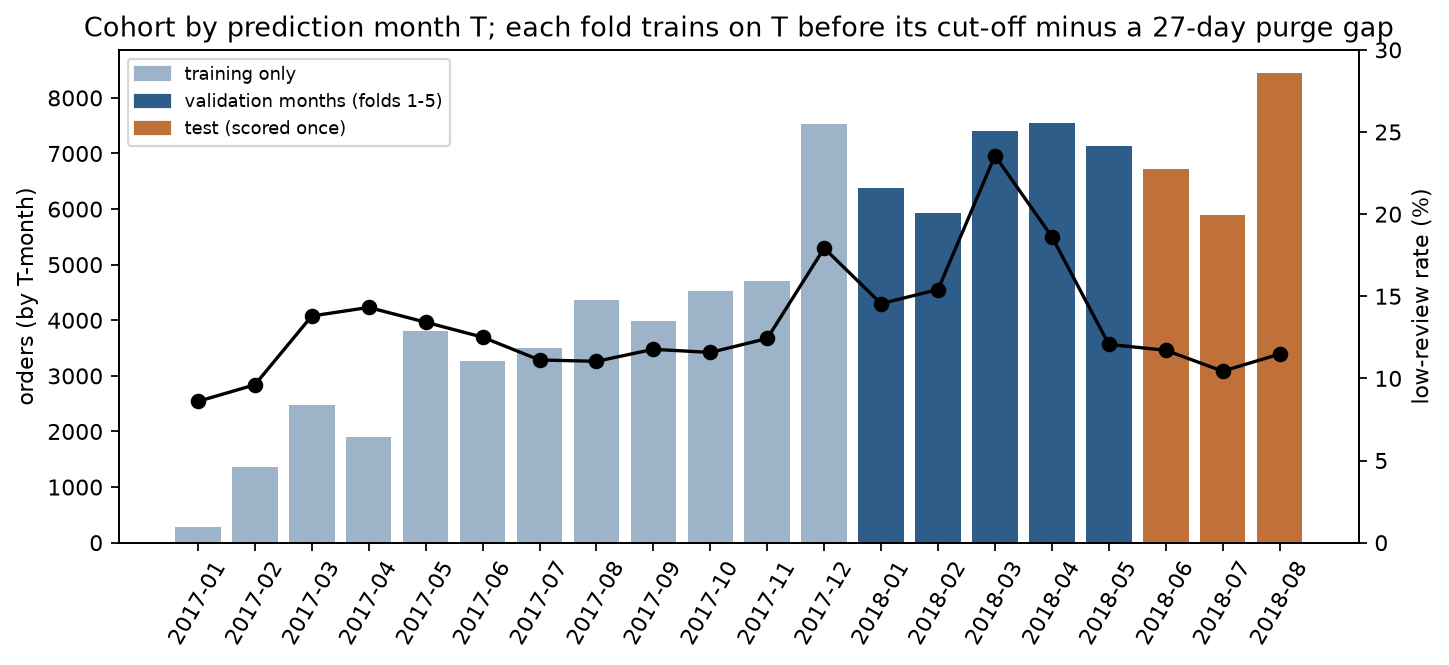

In [4]:
print(json.dumps(json.loads(config.GAP_FILE.read_text()), indent=2))
display(T("fold_table"))
F("01_windows_and_rates")

## 4. Model selection on the validation months

All families receive the same features. The search ranges below are reported in full (appendix table). Selection uses the highest mean validation PR-AUC over the five folds.

,family,search_space,candidates_scored,selection
0,logistic_base,fixed (no search),1,highest mean validation PR-AUC over 5 folds
1,logistic_tuned,"C in {0.001, 0.01, 0.1, 1, 10, 100, 1000}",7,highest mean validation PR-AUC over 5 folds
2,decision_tree,"max_depth integer uniform [3, 12]; min_samples...",20,highest mean validation PR-AUC over 5 folds
3,random_forest,"n_estimators integer uniform [300, 600]; max_d...",6,highest mean validation PR-AUC over 5 folds
4,catboost,"iterations in {300, 600, 1000}; learning_rate ...",6,highest mean validation PR-AUC over 5 folds


,family,cv_pr_auc_mean,cv_pr_auc_sd,cv_recall_at_capacity_mean,train_pr_auc_mean,params
0,random_forest,0.5463,0.0822,0.5934,0.5671,"{""model__max_depth"": 14, ""model__max_features""..."
1,catboost,0.5317,0.0727,0.5869,0.5342,"{""model__depth"": 4, ""model__iterations"": 1000,..."
2,logistic_tuned,0.5294,0.0731,0.5941,0.4732,"{""model__C"": 0.01}"
3,logistic_base,0.5278,0.0744,0.5919,0.4808,{}
4,decision_tree,0.5186,0.0798,0.5771,0.4975,"{""model__max_depth"": 10, ""model__min_samples_l..."
5,baseline_not_delivered_by_T,0.3832,0.0904,0.4994,NaN,{}
6,baseline_majority,0.1684,0.0443,0.2000,NaN,{}


fold,fold1,fold2,fold3,fold4,fold5
family,,,,,
baseline_majority,0.1455,0.1541,0.2356,0.1862,0.1207
baseline_not_delivered_by_T,0.3278,0.3628,0.5076,0.4382,0.2797
catboost,0.4843,0.5286,0.6317,0.5686,0.4451
decision_tree,0.4658,0.5168,0.6141,0.5779,0.4184
logistic_base,0.4938,0.5331,0.6147,0.5750,0.4222
logistic_tuned,0.4980,0.5309,0.6152,0.5771,0.4257
random_forest,0.4889,0.5407,0.6471,0.6074,0.4473


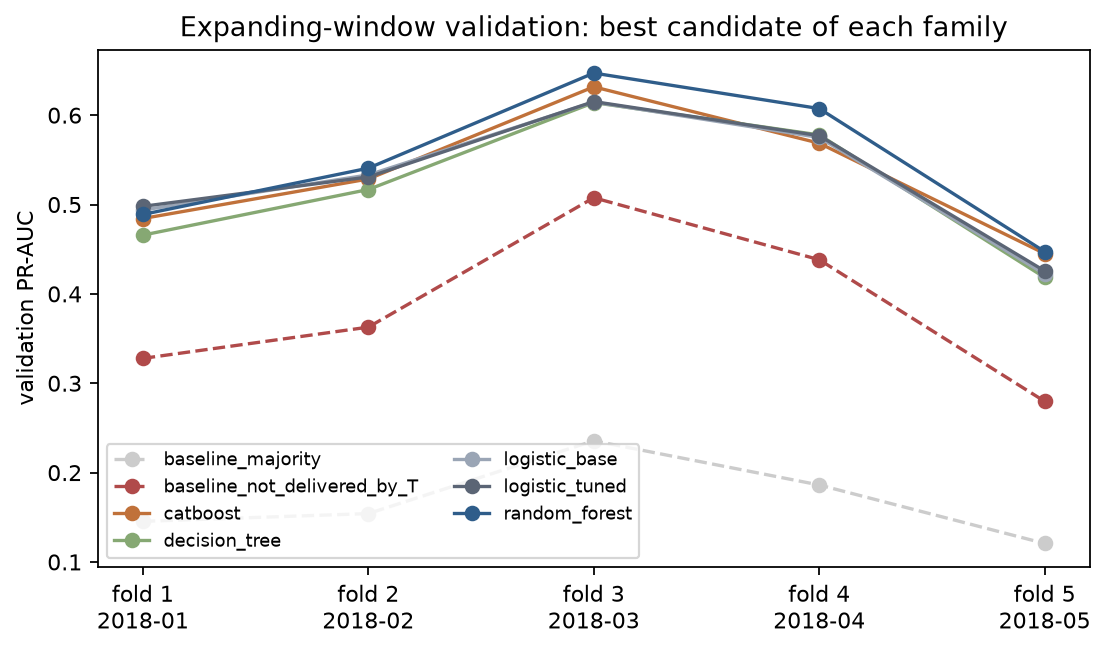

In [5]:
display(T("search_spaces"))
display(T("cv_family_summary"))
d = T("cv_fold_detail")
display(d.pivot_table(index="family", columns="fold", values="val_pr_auc").round(4))
F("02_cv_by_fold")

Training against validation PR-AUC for the best candidate of each family (an overfitting check):

In [6]:
display(d.dropna(subset=["train_pr_auc"]).groupby("family")[["train_pr_auc", "val_pr_auc"]].mean().round(4))
sel = json.loads(config.SELECTION_FILE.read_text())
print("selected:", sel["selected_family"], sel["params"])
print("frozen thresholds:", {k: round(v, 4) for k, v in sel["thresholds"].items() if k != "source"})

,train_pr_auc,val_pr_auc
family,,
catboost,0.5342,0.5317
decision_tree,0.4975,0.5186
logistic_base,0.4808,0.5278
logistic_tuned,0.4732,0.5294
random_forest,0.5671,0.5463


selected: random_forest {'model__max_depth': 14, 'model__max_features': 0.6290712064135155, 'model__min_samples_leaf': 80, 'model__n_estimators': 302}
frozen thresholds: {'capacity_threshold': 0.5475, 'f1_threshold': 0.6722}


## 5. Robustness of the gap

The chosen configuration with no gap, the 95th-percentile gap and the main 99th-percentile gap.

In [7]:
g = T("gap_sensitivity")
display(g.pivot_table(index="setting", columns="fold", values="val_pr_auc"))
display(g.pivot_table(index="setting", columns="fold", values="labels_answered_after_cutoff"))

fold,fold1,fold2,fold3,fold4,fold5
setting,,,,,
no gap (k=0),0.5137,0.5388,0.6484,0.6087,0.4517
q95 gap (k=9),0.5092,0.5365,0.6447,0.6100,0.4492
q99 gap (k=27) - main,0.4889,0.5407,0.6471,0.6074,0.4473


fold,fold1,fold2,fold3,fold4,fold5
setting,,,,,
no gap (k=0),0.01711,0.01865,0.01606,0.01325,0.01148
q95 gap (k=9),0.00585,0.00286,0.00294,0.00305,0.00224
q99 gap (k=27) - main,0.00240,0.00172,0.00174,0.00163,0.00148


## 6. What drives the predictions (May 2018 validation month)

Grouped permutation importance: the drop in PR-AUC when all columns of a group are shuffled together. It is computed on the last validation month, never on the test window.

,group,features,drop_mean,drop_sd
0,delivery_at_T,9,0.2890,0.0042
1,order,7,0.0591,0.0014
2,seller_history,6,0.0108,0.0008
3,promise,3,0.0065,0.0026
4,route_history,3,0.0034,0.0030
5,product,6,0.0020,0.0015
6,payment,4,0.0016,0.0006
7,calendar,4,0.0002,0.0001
8,geography,9,-0.0008,0.0032


,feature,group,drop_mean,drop_sd
0,is_delivered,delivery_at_T,0.0515,0.0037
1,n_items,order,0.0445,0.0030
2,wd_actual_delivery_time,delivery_at_T,0.0292,0.0061
3,delivery_vs_seller_prior,delivery_at_T,0.0214,0.0003
4,carrier_handover_days,delivery_at_T,0.0173,0.0007
5,actual_delivery_time,delivery_at_T,0.0157,0.0025
6,carrier_transit_days,delivery_at_T,0.0149,0.0017
7,carrier_shipped,delivery_at_T,0.0130,0.0009
8,wd_delivery_time_delta,delivery_at_T,0.0112,0.0030
9,delivery_time_delta,delivery_at_T,0.0103,0.0027


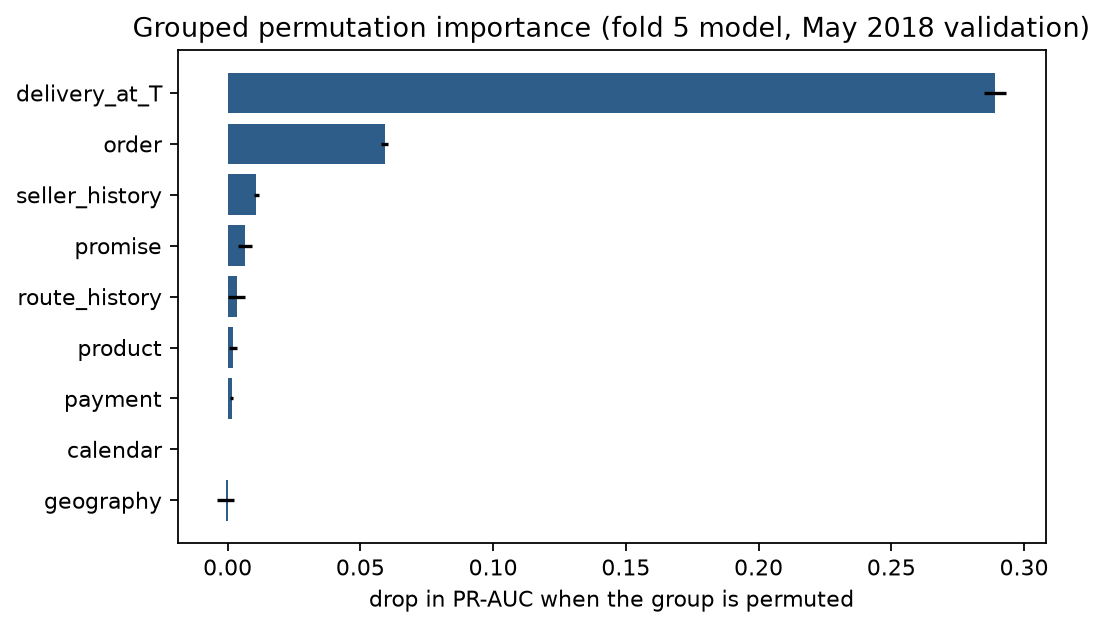

In [8]:
display(T("permutation_importance_groups").round(4))
display(T("permutation_importance_features").head(15).round(4))
F("04_group_importance")

## 7. Final test: Jun–Aug 2018, scored once

The `test` stage fits the selected configuration on every order with T before 1 Jun 2018 minus the gap, scores the test window once, and records the evaluation in `test_lock.json`.

,model,split,pr_auc,roc_auc,brier,positive_rate,recall_at_capacity,precision_at_capacity,lift_at_capacity,n
0,random_forest,train (in-sample),0.6099,0.8722,0.1358,0.1513,0.6482,0.4906,3.2412,70136.0
1,random_forest,CV mean (5 validation months),0.5463,NaN,NaN,NaN,0.5934,NaN,NaN,NaN
2,random_forest,test Jun-Aug 2018,0.3749,0.7392,0.1492,0.1126,0.5323,0.2996,2.6613,21058.0
3,baseline_majority,test Jun-Aug 2018,0.1126,NaN,NaN,0.1126,0.2000,NaN,NaN,21058.0
4,baseline_not_delivered_by_T,test Jun-Aug 2018,0.2099,0.6284,0.1245,0.1126,0.4057,0.2284,2.0287,21058.0


,rule,threshold,flag_rate,precision,recall,f1,balanced_accuracy
0,top 20% of the test window (capacity rule),0.4049,0.2000,0.2996,0.5323,0.3834,0.6872
1,frozen capacity threshold from validation,0.5475,0.1491,0.3532,0.4677,0.4025,0.6795
2,frozen F1 threshold from validation,0.6722,0.1127,0.4029,0.4032,0.4030,0.6637


,criterion,target,achieved,met
0,PR-AUC >= 2 x no-skill,0.2252,0.3749,True
1,recall in top 20% >= 50%,0.5000,0.5323,True


,t_month,pr_auc,roc_auc,brier,positive_rate,recall_at_capacity,precision_at_capacity,lift_at_capacity,n
0,2018-06,0.3409,0.7335,0.1548,0.1171,0.5229,0.3060,2.6145,6715
1,2018-07,0.3605,0.7102,0.1301,0.1044,0.4919,0.2568,2.4594,5901
2,2018-08,0.4145,0.7618,0.1582,0.1148,0.5738,0.3294,2.8689,8442


{
  "pr_auc_95ci": [
    0.3564207876197637,
    0.3966480416124372
  ],
  "recall_at_capacity_95ci": [
    0.5139848653821031,
    0.5509051961065683
  ],
  "n_boot": 1000
}


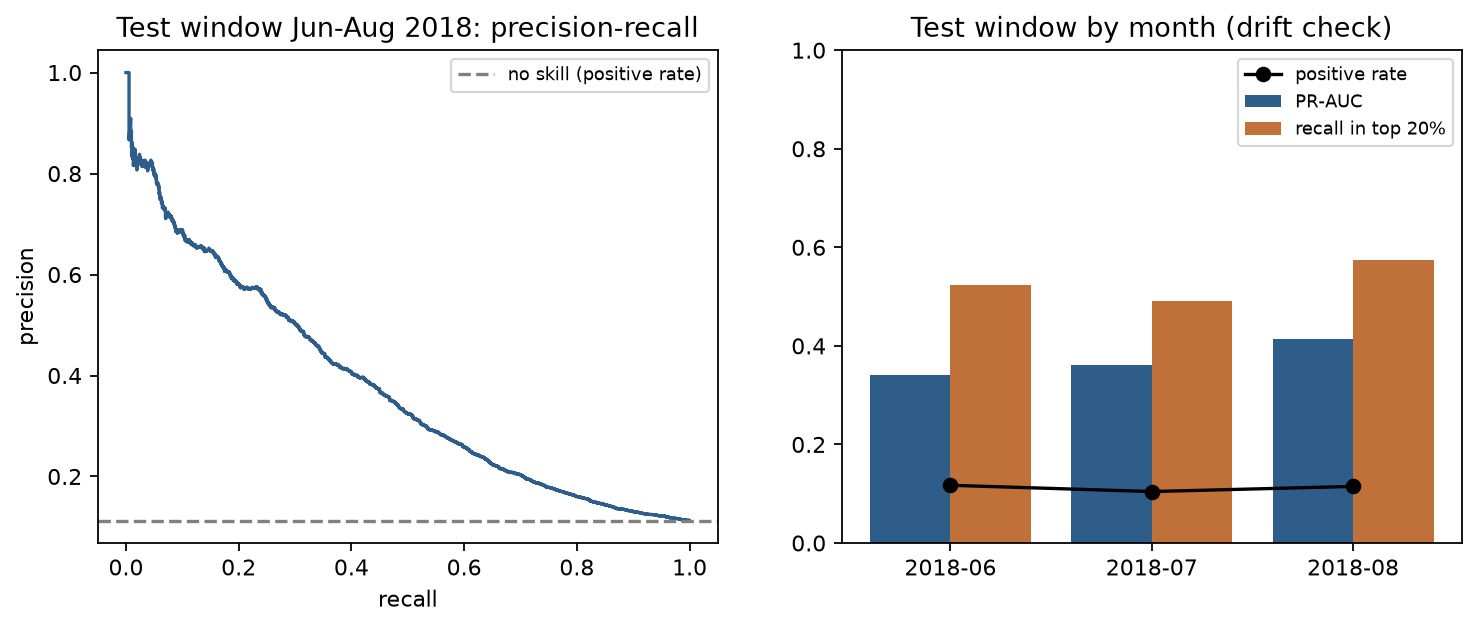

In [9]:
display(T("test_results"))
display(T("test_operating_points"))
display(T("success_criteria"))
display(T("test_by_month"))
print(json.dumps(json.loads((config.OUT_DIR / "test_summary.json").read_text())["bootstrap"], indent=2))
F("03_test_pr_and_months")

## 8. Reference: the Phase 2 stratified random split

The same cohort, features and hyperparameters; only the split changes. A random split mixes the test months into training, so its scores are expected to be optimistic.

,family,train_pr_auc,validation_pr_auc,test_pr_auc,test_roc_auc,test_recall_at_capacity,test_positive_rate,test_flag_rate_at_frozen_threshold
0,logistic_base,0.5026,0.4839,0.4846,0.7849,0.5854,0.1412,0.1925
1,logistic_tuned,0.4953,0.4831,0.4819,0.7817,0.5792,0.1412,0.1935
2,decision_tree,0.5226,0.4841,0.4795,0.7687,0.5796,0.1412,0.1963
3,random_forest,0.5905,0.5075,0.5021,0.7883,0.5924,0.1412,0.1932
4,catboost,0.5559,0.4922,0.4938,0.7873,0.5918,0.1412,0.1929


,procedure,train_pr_auc,test_pr_auc,test_roc_auc,test_recall_at_capacity,test_positive_rate,test_orders,test_pr_auc_over_no_skill
0,chronological (main): train T < Jun 2018 minus...,0.6099,0.3749,0.7392,0.5323,0.1126,21058,3.3299
1,"stratified random 67/33 (reference, Phase 2 pr...",0.5905,0.5021,0.7883,0.5924,0.1412,32072,3.5559


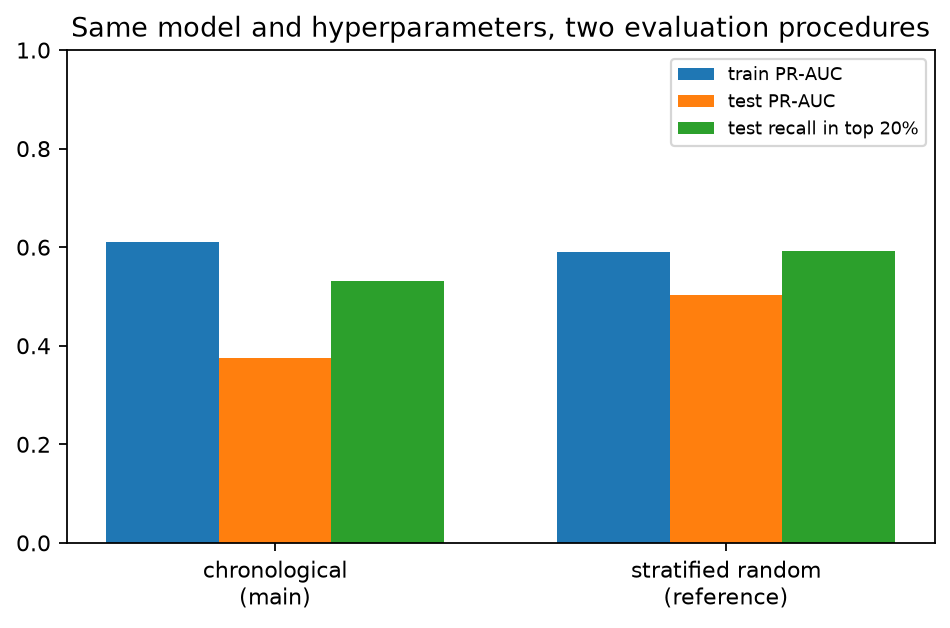

In [10]:
display(T("reference_random_split"))
display(T("chronological_vs_random"))
F("05_chronological_vs_random")

## 9. Deployment interface

`classification.score.score_orders` scores a batch of held-out orders and flags the top 20%. This is the function the Streamlit app calls.

In [11]:
from classification.score import load_bundle, score_orders
df = pipeline.load_table()
test_orders = df[df[config.TIME_COLUMN] >= config.TEST_START].head(10)
score_orders(test_orders, load_bundle())

,order_id,risk_score,risk_rank,flagged
76129,239a0e07e6d82c443b1ac00860f30c27,0.852291,9,False
76130,35b6b0272ca66bd5fef6d110463c40cc,0.876795,8,False
76131,b38b59f8e68e516569507e83c2d55c58,0.896636,3,False
76132,b399c199121f7dd129d7a6f908b95fc9,0.834795,10,False
76133,e3f2faf5604308ede614257aeb86ccf8,0.896055,4,False
76134,580ab1120013feff8019dae315cd8c9c,0.879369,7,False
76135,347d4f4caa9013e50f10654675fa35ef,0.939399,1,True
76136,d34b43bca6cc1cb6d49c06d6090770eb,0.889715,5,False
76137,50e46ab38a7ca83546cab50d4bca4835,0.922351,2,True
76138,dbf2c0164b592abca90f6c6817f37a9b,0.887063,6,False
